In [1]:
# Зависимости: numpy, pandas, matplotlib, seaborn, scipy, scikit-learn.
# При необходимости установите их в окружении Jupyter.


### 2.1 — Выбор датасета df0


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import gaussian_kde
from matplotlib.ticker import MaxNLocator, AutoMinorLocator, NullLocator
from IPython.display import display
import itertools
import warnings
warnings.filterwarnings('ignore')

# [2.1] Выбор датасета: 'iris' (sklearn, работает офлайн) или 'penguins' (Palmer Archipelago, seaborn)
DATASET = 'iris'

def load_df0(name):
    """Возвращает (df0, имя столбца класса)."""
    if name == 'iris':
        from sklearn.datasets import load_iris
        raw = load_iris(as_frame=True)
        df = raw.frame.copy()
        df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'target']
        df['species'] = df.pop('target').map(dict(enumerate(raw.target_names)))
        return df, 'species'
    if name == 'penguins':
        # столбцы: species, island, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, sex
        return sns.load_dataset('penguins'), 'species'
    raise ValueError(f'Неизвестный датасет: {name}')

df0, CLASS_COL = load_df0(DATASET)
print(f"Выбран датасет: {DATASET}")
print(df0)


Выбран датасет: iris
     sepal_length  sepal_width  petal_length  petal_width    species
0             5.1          3.5           1.4          0.2     setosa
1             4.9          3.0           1.4          0.2     setosa
2             4.7          3.2           1.3          0.2     setosa
3             4.6          3.1           1.5          0.2     setosa
4             5.0          3.6           1.4          0.2     setosa
..            ...          ...           ...          ...        ...
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica

[150 rows x 5 columns]


### 2.2 — Статистика по датасету


In [3]:
def get_dataset_stats(df, class_col, title='df0'):
    print(f"=== [2.2] СТАТИСТИКА ПО ДАТАСЕТУ {title} ===")
    print(f"Размерность датасета: {df.shape[0]} объектов, {df.shape[1]} признаков (включая класс)\n")

    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    print("--- Типы признаков ---")
    display(df.dtypes.astype(str).rename('dtype').to_frame())

    print("--- Количество классов и объектов в каждом из классов ---")
    print(f"Количество классов: {df[class_col].nunique()}")
    display(df[class_col].value_counts(dropna=False).rename('n_objects').to_frame())

    # Число объектов с NaN / 0 по классам (по каждому признаку и «хотя бы в одном признаке»)
    nan_by_class = df[num_cols].isna().groupby(df[class_col]).sum()
    nan_by_class['any_feature'] = df[num_cols].isna().any(axis=1).groupby(df[class_col]).sum()
    zero_by_class = (df[num_cols] == 0).groupby(df[class_col]).sum()
    zero_by_class['any_feature'] = (df[num_cols] == 0).any(axis=1).groupby(df[class_col]).sum()

    print("--- Число объектов с NaN по классам ---")
    display(nan_by_class)
    print("--- Число объектов с 0 по классам ---")
    display(zero_by_class)

    print("--- Основные статистические оценки (Mean, Std, Median, IQR, Range, Skew, Kurtosis) ---")
    stats_df = df[num_cols].describe().T
    stats_df['IQR'] = stats_df['75%'] - stats_df['25%']
    stats_df['Range'] = stats_df['max'] - stats_df['min']
    stats_df['skew'] = df[num_cols].skew()
    stats_df['kurtosis'] = df[num_cols].kurt()
    stats_df['n_unique'] = df[num_cols].nunique()
    stats_df['n_nan'] = df[num_cols].isna().sum()
    stats_df = stats_df.rename(columns={'50%': 'median'})
    display(stats_df[['count', 'mean', 'std', 'min', 'median', 'max', 'IQR', 'Range',
                      'skew', 'kurtosis', 'n_unique', 'n_nan']].round(3))

get_dataset_stats(df0, CLASS_COL)


=== [2.2] СТАТИСТИКА ПО ДАТАСЕТУ df0 ===
Размерность датасета: 150 объектов, 5 признаков (включая класс)

--- Типы признаков ---


,dtype
sepal_length,float64
sepal_width,float64
petal_length,float64
petal_width,float64
species,str


--- Количество классов и объектов в каждом из классов ---
Количество классов: 3


,n_objects
species,
setosa,50
versicolor,50
virginica,50


--- Число объектов с NaN по классам ---


,sepal_length,sepal_width,petal_length,petal_width,any_feature
species,,,,,
setosa,0,0,0,0,0
versicolor,0,0,0,0,0
virginica,0,0,0,0,0


--- Число объектов с 0 по классам ---


,sepal_length,sepal_width,petal_length,petal_width,any_feature
species,,,,,
setosa,0,0,0,0,0
versicolor,0,0,0,0,0
virginica,0,0,0,0,0


--- Основные статистические оценки (Mean, Std, Median, IQR, Range, Skew, Kurtosis) ---


,count,mean,std,min,median,max,IQR,Range,skew,kurtosis,n_unique,n_nan
sepal_length,150.0,5.843,0.828,4.3,5.80,7.9,1.3,3.6,0.315,-0.552,35,0
sepal_width,150.0,3.057,0.436,2.0,3.00,4.4,0.5,2.4,0.319,0.228,23,0
petal_length,150.0,3.758,1.765,1.0,4.35,6.9,3.5,5.9,-0.275,-1.402,43,0
petal_width,150.0,1.199,0.762,0.1,1.30,2.5,1.5,2.4,-0.103,-1.341,22,0


### 2.3 — UpSet plot: пропуски и повторяющиеся значения


df0: пропусков нет; ненулевых пересечений пропусков нет.
--- Объектов, у которых значение повторяется хотя бы в одном признаке: 150 из 150 ---


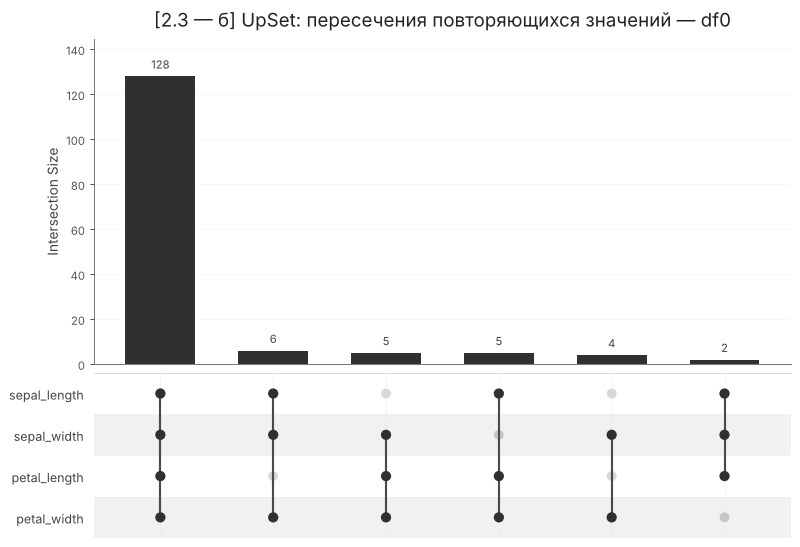

In [4]:
def upset_plot_from_indicators(indicators, title, min_count=1):
    """Строгая визуализация UpSet в спокойном стиле по референсу пользователя."""
    indicators = indicators.astype(bool).copy()
    features = list(indicators.columns)

    counts = (
        indicators.groupby(features, sort=False)
        .size()
        .reset_index(name='count')
    )
    counts = (
        counts[counts['count'] >= min_count]
        .sort_values('count', ascending=False)
        .reset_index(drop=True)
    )

    if counts.empty:
        print(f'{title}: нет ненулевых пересечений.')
        return

    x = np.arange(len(counts))

    # Высота матрицы увеличивается вместе с числом признаков,
    # а ширина — с количеством комбинаций.
    fig = plt.figure(
        figsize=(max(10, 0.62 * len(counts) + 3), 7.2),
        facecolor='white'
    )
    gs = fig.add_gridspec(
        2, 1,
        height_ratios=[3.25, 1.65],
        hspace=0.035
    )
    ax_bar = fig.add_subplot(gs[0])
    ax_mat = fig.add_subplot(gs[1], sharex=ax_bar)

    # Верхняя часть: спокойные тёмно-серые столбцы, как в референсе.
    bar_color = '#303030'
    ax_bar.bar(
        x, counts['count'],
        width=0.62,
        color=bar_color,
        edgecolor='none',
        linewidth=0
    )

    # Числа над столбцами.
    ymax = counts['count'].max()
    ax_bar.set_ylim(0, ymax * 1.13 if ymax > 0 else 1)

    for j, value in enumerate(counts['count']):
        ax_bar.text(
            j, value + ymax * 0.018,
            str(int(value)),
            ha='center', va='bottom',
            fontsize=9, color='#444444'
        )

    ax_bar.set_ylabel(
        'Intersection Size',
        fontsize=11,
        color='#444444'
    )
    ax_bar.set_title(
        title,
        fontsize=15,
        color='#222222',
        pad=10
    )

    ax_bar.spines['top'].set_visible(False)
    ax_bar.spines['right'].set_visible(False)
    ax_bar.spines['left'].set_color('#777777')
    ax_bar.spines['bottom'].set_color('#777777')
    ax_bar.tick_params(axis='y', colors='#555555', labelsize=9)
    ax_bar.tick_params(axis='x', bottom=False, labelbottom=False)
    ax_bar.grid(axis='y', linestyle='-', linewidth=0.6, alpha=0.13)
    ax_bar.set_axisbelow(True)

    # Нижняя часть: чередующиеся белые/светло-серые строки.
    white_row = '#ffffff'
    gray_row = '#f1f1f1'

    for i in range(len(features)):
        if i % 2 == 1:
            ax_mat.axhspan(
                i - 0.5, i + 0.5,
                facecolor=gray_row,
                edgecolor='none',
                zorder=0
            )
        else:
            ax_mat.axhspan(
                i - 0.5, i + 0.5,
                facecolor=white_row,
                edgecolor='none',
                zorder=0
            )

    # Мягкая горизонтальная граница между строками.
    for i in range(len(features) + 1):
        ax_mat.axhline(
            i - 0.5,
            color='#eeeeee',
            linewidth=0.55,
            zorder=0.5
        )

    # Неактивная точка должна быть видна и на белой, и на серой строке,
    # но не перетягивать внимание на себя.
    inactive_on_white = '#d8d8d8'
    inactive_on_gray = '#c7c7c7'
    active_color = '#303030'
    connector_color = '#4a4a4a'

    for j in x:
        active = [
            i for i, f in enumerate(features)
            if bool(counts.loc[j, f])
        ]
        inactive = [
            i for i in range(len(features))
            if i not in active
        ]

        for i in inactive:
            point_color = (
                inactive_on_gray if i % 2 == 1
                else inactive_on_white
            )
            ax_mat.scatter(
                j, i,
                s=62,
                marker='o',
                facecolor=point_color,
                edgecolor='none',
                linewidth=0,
                zorder=2
            )

        # Активные точки — тёмные, но без чёрной обводки.
        if active:
            ax_mat.scatter(
                [j] * len(active),
                active,
                s=67,
                marker='o',
                facecolor=active_color,
                edgecolor='none',
                linewidth=0,
                zorder=4
            )

            # Соединяем только активные точки.
            if len(active) > 1:
                ax_mat.plot(
                    [j, j],
                    [min(active), max(active)],
                    color=connector_color,
                    linewidth=1.7,
                    solid_capstyle='round',
                    zorder=3
                )

    ax_mat.set_yticks(range(len(features)))
    ax_mat.set_yticklabels(
        features,
        fontsize=10,
        color='#444444'
    )
    ax_mat.set_ylim(
        len(features) - 0.5,
        -0.5
    )

    ax_mat.set_xticks(x)
    ax_mat.set_xticklabels([])

    ax_mat.set_xlabel('')
    ax_mat.set_ylabel('')

    ax_mat.spines['top'].set_color('#dddddd')
    ax_mat.spines['bottom'].set_visible(False)
    ax_mat.spines['left'].set_visible(False)
    ax_mat.spines['right'].set_visible(False)

    ax_mat.tick_params(axis='x', bottom=False, top=False, length=0)
    ax_mat.tick_params(axis='y', left=False, length=0, pad=8)

    ax_mat.grid(
        axis='x',
        linestyle='-',
        linewidth=0.5,
        color='#e5e5e5',
        alpha=0.65
    )
    ax_mat.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


def plot_upset_missing_and_repeats(df, dataset_name='df0', section='2.3'):
    """(а) пересечения пропусков по признакам; (б) пересечения повторяющихся значений
    (значение встречается в признаке более одного раза) по количественным признакам."""
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    # (а) пропуски — по всем столбцам датасета (кроме столбца класса)
    miss_cols = [c for c in df.columns if c != CLASS_COL]
    missing = df[miss_cols].isna()
    if missing.any().any():
        upset_plot_from_indicators(
            missing,
            f'[{section} — а] UpSet: пересечения пропусков — {dataset_name}'
        )
    else:
        print(f'{dataset_name}: пропусков нет; ненулевых пересечений пропусков нет.')

    # (б) повторы внутри признака (NaN повтором не считаем)
    repeats = pd.DataFrame({
        c: df[c].duplicated(keep=False) & df[c].notna() for c in num_cols
    })
    print(f'--- Объектов, у которых значение повторяется хотя бы в одном признаке: '
          f'{int(repeats.any(axis=1).sum())} из {len(df)} ---')
    upset_plot_from_indicators(
        repeats,
        f'[{section} — б] UpSet: пересечения повторяющихся значений — {dataset_name}'
    )

plot_upset_missing_and_repeats(df0, dataset_name='df0')


### 2.4 — Отбор классов и признаков, датасет df0m


In [5]:
# [2.4] Выбор трёх классов и четырёх количественных признаков (можно изменить)
SELECTED_CLASSES = list(df0[CLASS_COL].dropna().unique()[:3])
SELECTED_FEATURES = df0.select_dtypes(include=[np.number]).columns.tolist()[:4]

# Удаляем объекты, у которых не определено хотя бы одно из выбранных 4 значений
df0m = (df0[df0[CLASS_COL].isin(SELECTED_CLASSES)]
        .dropna(subset=SELECTED_FEATURES)
        .reset_index(drop=True))

# Единая раскраска / маркеры классов для всех графиков
CLASS_COLORS = dict(zip(SELECTED_CLASSES, sns.color_palette('Set1', len(SELECTED_CLASSES))))
CLASS_MARKERS = dict(zip(SELECTED_CLASSES, ['o', 's', '^', 'D', 'v'][:len(SELECTED_CLASSES)]))

print("=== [2.4] ОТФИЛЬТРОВАННЫЙ ДАТАСЕТ df0m ===")
print(f"Классы: {SELECTED_CLASSES}")
print(f"Признаки: {SELECTED_FEATURES}")
print(f"df0: {len(df0)} объектов -> df0m: {len(df0m)} объектов (удалено {len(df0) - len(df0m)})")
display(df0m[CLASS_COL].value_counts().rename('n_objects').to_frame())


=== [2.4] ОТФИЛЬТРОВАННЫЙ ДАТАСЕТ df0m ===
Классы: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Признаки: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
df0: 150 объектов -> df0m: 150 объектов (удалено 0)


,n_objects
species,
setosa,50
versicolor,50
virginica,50


### 2.5 — Корреляции Пирсона: df0 и df0m


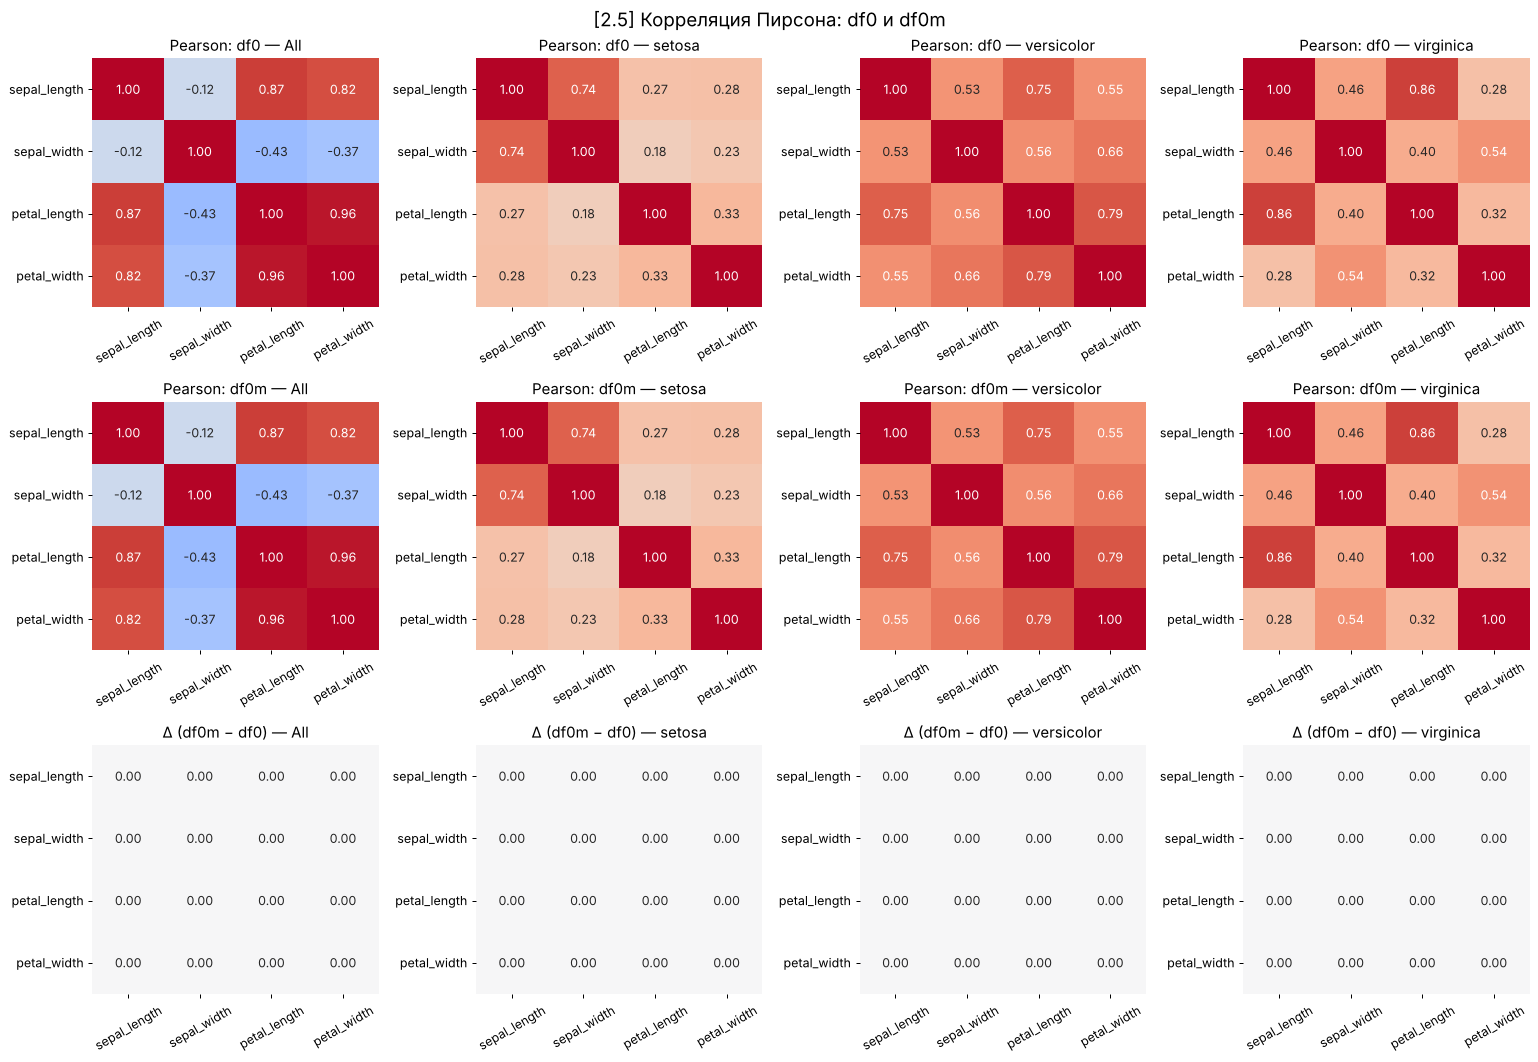

In [6]:
def plot_pearson_df0_vs_df0m(df_a, df_b, features, class_col, classes,
                             names=('df0', 'df0m')):
    """Строки: df0, df0m и разность (df0m − df0).
    Столбцы: весь датасет и каждый класс отдельно. Пропуски — попарное удаление (pandas)."""
    cols = ['All'] + list(classes)
    fig, axes = plt.subplots(3, len(cols), figsize=(4.3 * len(cols), 12), squeeze=False)

    def corr_for(df, col):
        sub = df if col == 'All' else df[df[class_col] == col]
        return sub[features].corr(method='pearson')

    for j, col in enumerate(cols):
        ca, cb = corr_for(df_a, col), corr_for(df_b, col)
        sns.heatmap(ca, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
                    ax=axes[0, j], cbar=False)
        axes[0, j].set_title(f'Pearson: {names[0]} — {col}')
        sns.heatmap(cb, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
                    ax=axes[1, j], cbar=False)
        axes[1, j].set_title(f'Pearson: {names[1]} — {col}')
        sns.heatmap(cb - ca, annot=True, fmt='.2f', cmap='PuOr', center=0, vmin=-0.5, vmax=0.5,
                    ax=axes[2, j], cbar=False)
        axes[2, j].set_title(f'Δ ({names[1]} − {names[0]}) — {col}')
        for i in range(3):
            axes[i, j].tick_params(axis='x', rotation=30)

    fig.suptitle('[2.5] Корреляция Пирсона: df0 и df0m', fontsize=15)
    plt.tight_layout()
    plt.show()

plot_pearson_df0_vs_df0m(df0, df0m, SELECTED_FEATURES, CLASS_COL, SELECTED_CLASSES)


### 2.6 — Попарная визуализация признаков по классам


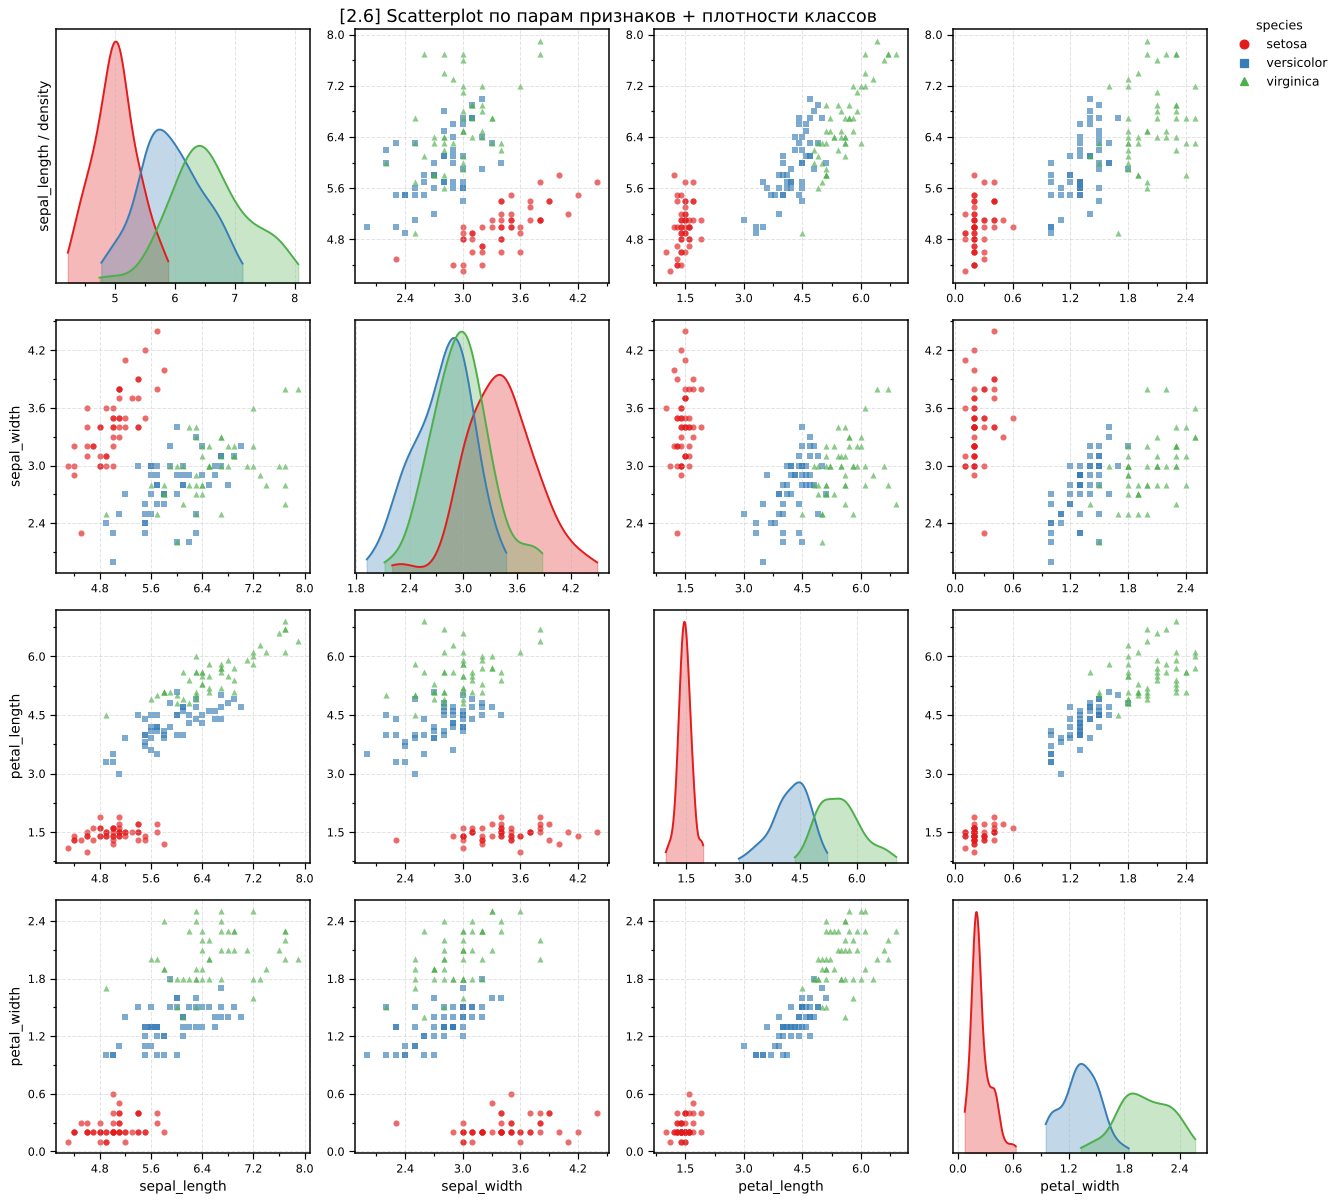

In [7]:
# Параметры оформления, регулируемые пользователем (используются в 2.6–2.8 и 2.12)
DEFAULT_STYLE = dict(
    color_axes='black', lw_axes=1.2,      # цвет и толщина осей
    n_major=5, n_minor=1,                 # число больших делений; число малых между большими
    grid=True, grid_alpha=0.35,           # сетка
    square=True,                          # квадратная форма каждого рисунка
    font_family='DejaVu Sans',            # тип шрифта
    font_size_labels=11, font_size_ticks=9,
    font_size_title=14, font_size_legend=10,
    show_legend=True, show_title=True,    # отключаемость легенды и заглавия
    alpha=0.65, point_size=24,            # прозрачность и размер точек
)

def apply_axis_style(ax, st):
    for sp in ax.spines.values():
        sp.set_color(st['color_axes'])
        sp.set_linewidth(st['lw_axes'])
    ax.tick_params(which='both', color=st['color_axes'], width=st['lw_axes'] * 0.8)
    ax.tick_params(which='major', length=5, labelsize=st['font_size_ticks'])
    ax.tick_params(which='minor', length=2.5)
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(MaxNLocator(st['n_major']))
        if st['n_minor'] > 0:
            axis.set_minor_locator(AutoMinorLocator(st['n_minor'] + 1))
        else:
            axis.set_minor_locator(NullLocator())
    ax.grid(st['grid'], which='major', linestyle='--', alpha=st['grid_alpha'])
    if st['square']:
        ax.set_box_aspect(1)

def plot_pairgrid(df, features, class_col, classes, colors, markers, style=None,
                  regression=False, show_conf=False, show_pred=True, level=0.95,
                  title=None):
    """Матрица k×k: вне диагонали — scatterplot (классы разной формы/цвета),
    на диагонали — плотность каждого класса по оси признака.
    regression=True добавляет линию регрессии каждого класса и (опционально) полосы."""
    st = {**DEFAULT_STYLE, **(style or {})}
    k = len(features)
    with plt.rc_context({'font.family': st['font_family']}):
        fig, axes = plt.subplots(k, k, figsize=(3.4 * k, 3.4 * k), squeeze=False)
        for i, yc in enumerate(features):
            for j, xc in enumerate(features):
                ax = axes[i, j]
                apply_axis_style(ax, st)
                for cls in classes:
                    sub = df[df[class_col] == cls]
                    if i == j:
                        vals = sub[xc].dropna()
                        pad = 0.25 * vals.std()
                        xg = np.linspace(vals.min() - pad, vals.max() + pad, 200)
                        yk = gaussian_kde(vals)(xg)
                        ax.fill_between(xg, 0, yk, color=colors[cls], alpha=0.3)
                        ax.plot(xg, yk, color=colors[cls], lw=1.5)
                    else:
                        ax.scatter(sub[xc], sub[yc], color=colors[cls], marker=markers[cls],
                                   s=st['point_size'], alpha=st['alpha'], linewidths=0)
                        if regression:
                            fit = linreg_fit(sub[xc], sub[yc])
                            xg = np.linspace(fit['x'].min(), fit['x'].max(), 100)
                            line, lo_c, hi_c, lo_p, hi_p = reg_bands(fit, xg, level)
                            ax.plot(xg, line, color=colors[cls], lw=1.8)
                            if show_pred:
                                ax.fill_between(xg, lo_p, hi_p, color=colors[cls], alpha=0.12, lw=0)
                            if show_conf:
                                ax.fill_between(xg, lo_c, hi_c, color=colors[cls], alpha=0.30, lw=0)
                if i == j:
                    ax.set_yticks([])
                    ax.set_ylim(bottom=0)
                if i == k - 1:
                    ax.set_xlabel(xc, fontsize=st['font_size_labels'])
                if j == 0:
                    ax.set_ylabel(yc if i != 0 else f'{yc} / density',
                                  fontsize=st['font_size_labels'])
        if st['show_legend']:
            handles = [plt.Line2D([], [], marker=markers[c], color=colors[c], linestyle='',
                                  markersize=7, label=str(c)) for c in classes]
            fig.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.0, 0.98),
                       fontsize=st['font_size_legend'], title=class_col, frameon=False)
        if st['show_title']:
            fig.suptitle(title or 'Pairwise scatterplots & class densities',
                         fontsize=st['font_size_title'])
        plt.tight_layout()
        plt.show()

plot_pairgrid(df0m, SELECTED_FEATURES, CLASS_COL, SELECTED_CLASSES,
              CLASS_COLORS, CLASS_MARKERS, title='[2.6] Scatterplot по парам признаков + плотности классов')


### 2.7 — Линейная регрессия для одного класса и пары признаков


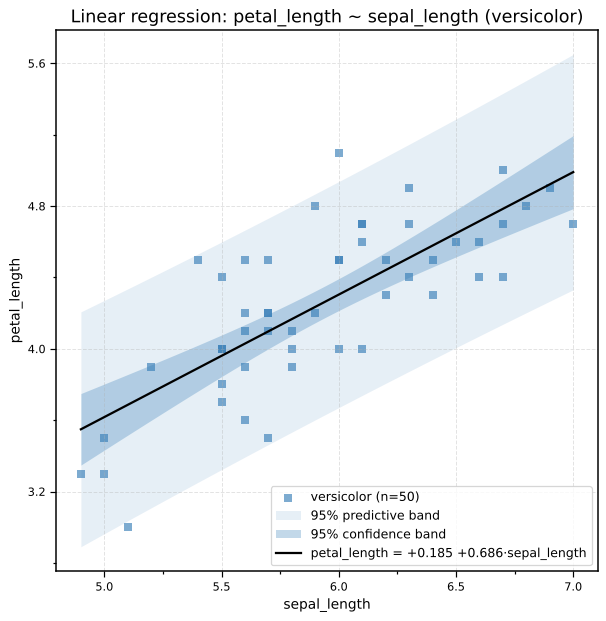

In [8]:
def linreg_fit(x, y):
    """МНК-регрессия y = b0 + b1·x (попарное удаление NaN) со всеми величинами для критериев."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    m = ~(np.isnan(x) | np.isnan(y))
    x, y = x[m], y[m]
    n = len(x)
    xm, ym = x.mean(), y.mean()
    Sxx = ((x - xm) ** 2).sum()
    b1 = ((x - xm) * (y - ym)).sum() / Sxx
    b0 = ym - b1 * xm
    rss = ((y - (b0 + b1 * x)) ** 2).sum()
    tss = ((y - ym) ** 2).sum()
    return dict(x=x, y=y, n=n, xm=xm, ym=ym, Sxx=Sxx, b0=b0, b1=b1,
                rss=rss, tss=tss, r2=1 - rss / tss, s2=rss / (n - 2),
                r=np.corrcoef(x, y)[0, 1])

def reg_bands(fit, xg, level=0.95):
    """Линия регрессии, доверительная (confidence) и прогнозная (predictive) полосы."""
    n = fit['n']
    t = stats.t.ppf(1 - (1 - level) / 2, n - 2)
    line = fit['b0'] + fit['b1'] * xg
    h = 1.0 / n + (xg - fit['xm']) ** 2 / fit['Sxx']
    se_conf = np.sqrt(fit['s2'] * h)          # неопределённость среднего E[y|x]
    se_pred = np.sqrt(fit['s2'] * (1 + h))    # неопределённость нового наблюдения
    return line, line - t * se_conf, line + t * se_conf, line - t * se_pred, line + t * se_pred

def plot_regression_single(df, cls, x_col, y_col, class_col, color, marker,
                           style=None, show_line=True, show_conf=True, show_pred=True,
                           show_corr=False, level=0.95, title=None):
    """Одиночный scatterplot с регрессией; полосы включаются/отключаются пользователем."""
    st = {**DEFAULT_STYLE, **(style or {})}
    sub = df[df[class_col] == cls]
    fit = linreg_fit(sub[x_col], sub[y_col])
    with plt.rc_context({'font.family': st['font_family']}):
        fig, ax = plt.subplots(figsize=(7, 7) if st['square'] else (9, 6))
        apply_axis_style(ax, st)
        ax.scatter(fit['x'], fit['y'], color=color, marker=marker, s=st['point_size'] * 1.6,
                   alpha=st['alpha'], linewidths=0, label=f'{cls} (n={fit["n"]})')
        if show_line or show_conf or show_pred:
            xg = np.linspace(fit['x'].min(), fit['x'].max(), 200)
            line, lo_c, hi_c, lo_p, hi_p = reg_bands(fit, xg, level)
            if show_pred:
                ax.fill_between(xg, lo_p, hi_p, color=color, alpha=0.12, lw=0,
                                label=f'{int(level*100)}% predictive band')
            if show_conf:
                ax.fill_between(xg, lo_c, hi_c, color=color, alpha=0.30, lw=0,
                                label=f'{int(level*100)}% confidence band')
            if show_line:
                ax.plot(xg, line, color='black', lw=1.8,
                        label=f'{y_col} = {fit["b0"]:+.3f} {fit["b1"]:+.3f}·{x_col}')
        if show_corr:
            ax.text(0.04, 0.96, f'Pearson r = {fit["r"]:.3f}', transform=ax.transAxes,
                    va='top', fontsize=st['font_size_labels'],
                    bbox=dict(facecolor='white', edgecolor=st['color_axes'], alpha=0.85))
        ax.set_xlabel(x_col, fontsize=st['font_size_labels'])
        ax.set_ylabel(y_col, fontsize=st['font_size_labels'])
        if st['show_legend']:
            ax.legend(fontsize=st['font_size_legend'], loc='lower right')
        if st['show_title']:
            ax.set_title(title or f'Linear regression: {y_col} ~ {x_col} ({cls})',
                         fontsize=st['font_size_title'])
        plt.tight_layout()
        plt.show()

# Выбор класса и пары признаков пользователем
REG_CLASS = SELECTED_CLASSES[1]
REG_X, REG_Y = SELECTED_FEATURES[0], SELECTED_FEATURES[2]

plot_regression_single(df0m, REG_CLASS, REG_X, REG_Y, CLASS_COL,
                       CLASS_COLORS[REG_CLASS], CLASS_MARKERS[REG_CLASS],
                       show_line=True, show_conf=True, show_pred=True, level=0.95)


### 2.8 — Попарная визуализация с линиями регрессии и прогнозными полосами


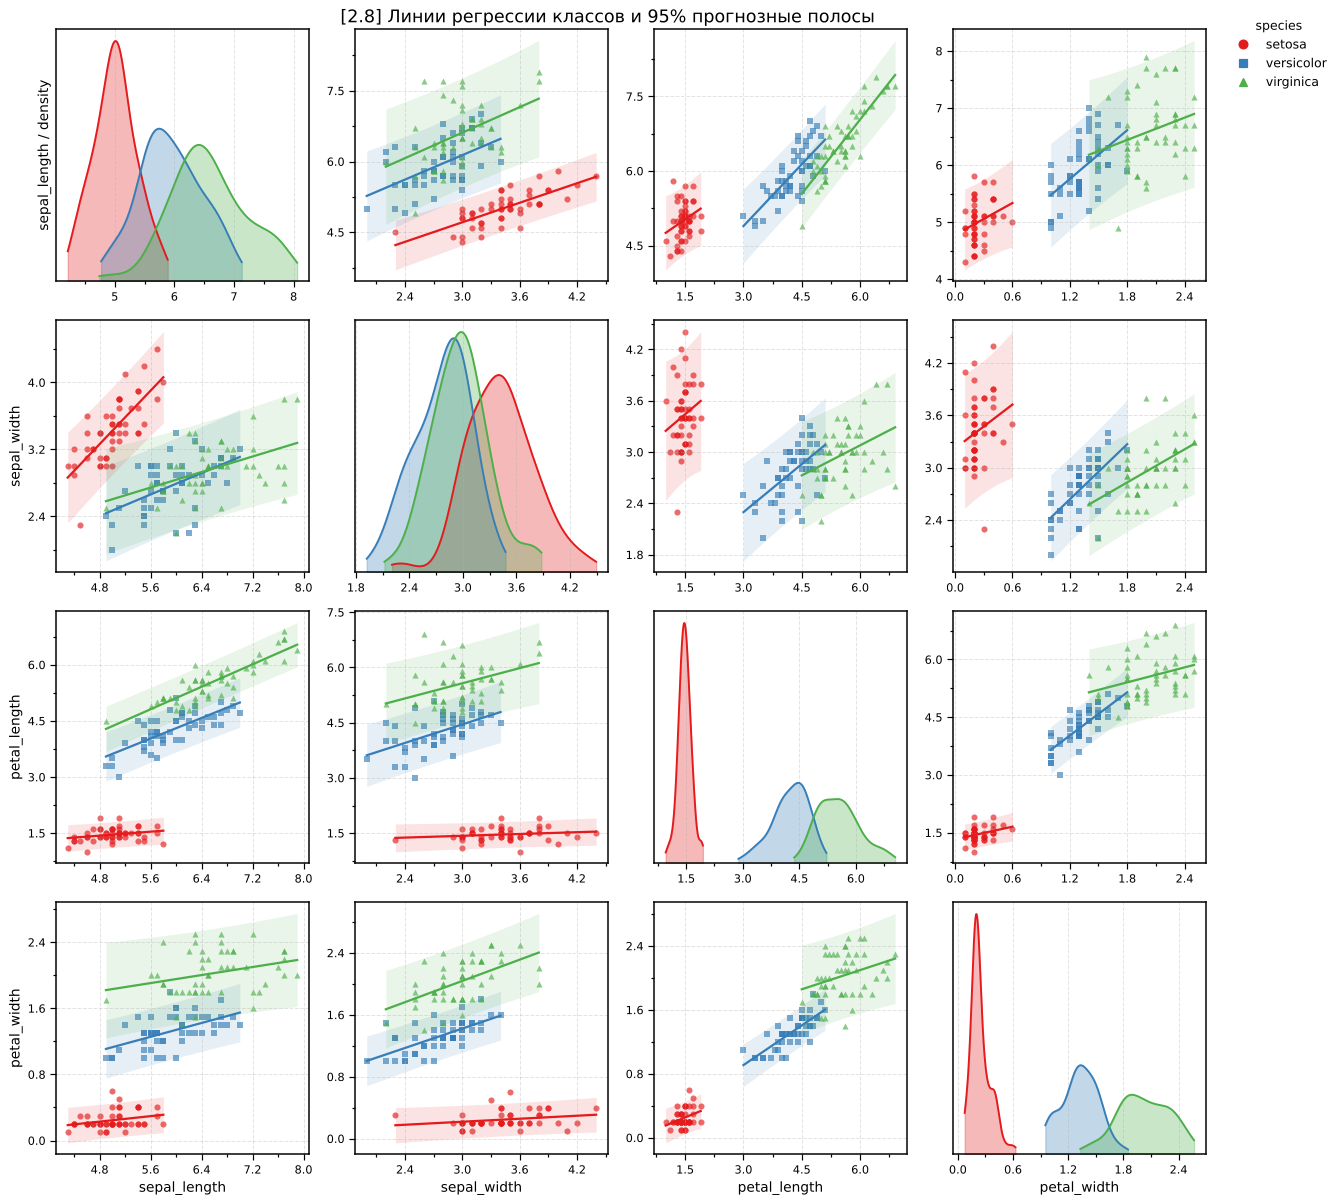

In [9]:
# show_pred / show_conf включают и отключают полосы перед отображением
plot_pairgrid(df0m, SELECTED_FEATURES, CLASS_COL, SELECTED_CLASSES,
              CLASS_COLORS, CLASS_MARKERS,
              regression=True, show_pred=True, show_conf=False, level=0.95,
              title='[2.8] Линии регрессии классов и 95% прогнозные полосы')


### 2.9 — Формулы регрессий и критерии Вальда, LR, score


In [10]:
def regression_tests(fit):
    """Проверка H0: b1 = 0 для y = b0 + b1·x.
    Асимптотические статистики (RSS0 = TSS — модель без наклона, RSS1 — полная модель):
        Wald  W  = n·(RSS0 − RSS1)/RSS1
        LR    LR = n·ln(RSS0/RSS1)
        Score S  = n·(RSS0 − RSS1)/RSS0 = n·R²
    Малая выборка: каждую приводим к F-форме F = stat/df1 · (n − p)/n, F ~ F(df1, df2),
    df1 = 1, df2 = n − 2 (для Вальда это ровно t² коэффициента наклона)."""
    n, rss, tss = fit['n'], fit['rss'], fit['tss']
    df1, df2 = 1, n - 2
    raw = {'Wald': n * (tss - rss) / rss,
           'LR': n * np.log(tss / rss),
           'Score': n * (tss - rss) / tss}
    out = {}
    for name, val in raw.items():
        F = val / df1 * df2 / n
        out[name] = (F, df1, df2, stats.f.sf(F, df1, df2))
    return out

def regression_report(df, features, class_col, classes):
    rows = []
    for cls in classes:
        sub = df[df[class_col] == cls]
        for xc in features:
            for yc in features:
                if xc == yc:
                    continue
                fit = linreg_fit(sub[xc], sub[yc])
                tests = regression_tests(fit)
                row = {('', 'class'): cls,
                       ('', 'regression'): f"{yc} = {fit['b0']:+.3f} {fit['b1']:+.3f}·{xc}",
                       ('', 'n'): fit['n'],
                       ('', 'R²'): f"{fit['r2']:.3f}"}
                for name, (F, d1, d2, p) in tests.items():
                    row[(name, 'F')] = f'{F:.2f}'
                    row[(name, 'df1')] = d1
                    row[(name, 'df2')] = d2
                    row[(name, 'p')] = f'{p:.2e}'
                rows.append(row)
    rep = pd.DataFrame(rows)
    rep.columns = pd.MultiIndex.from_tuples(rep.columns)
    return rep

print("=== [2.9] ЛИНЕЙНЫЕ РЕГРЕССИИ (y ~ x) И КРИТЕРИИ ЗНАЧИМОСТИ НАКЛОНА ===")
report_29 = regression_report(df0m, SELECTED_FEATURES, CLASS_COL, SELECTED_CLASSES)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.width', 250):
    display(report_29)


=== [2.9] ЛИНЕЙНЫЕ РЕГРЕССИИ (y ~ x) И КРИТЕРИИ ЗНАЧИМОСТИ НАКЛОНА ===


Wald                       LR                    Score                  
         class                                 regression   n     R²       F df1 df2         p      F df1 df2         p      F df1 df2         p
0       setosa   sepal_width = -0.569 +0.799·sepal_length  50  0.551   58.99   1  48  6.71e-10  38.48   1  48  1.23e-07  26.47   1  48  4.92e-06
1       setosa  petal_length = +0.803 +0.132·sepal_length  50  0.071    3.69   1  48  6.07e-02   3.55   1  48  6.54e-02   3.43   1  48  7.03e-02
2       setosa   petal_width = -0.170 +0.083·sepal_length  50  0.077    4.02   1  48  5.05e-02   3.86   1  48  5.51e-02   3.71   1  48  5.99e-02
3       setosa   sepal_length = +2.639 +0.690·sepal_width  50  0.551   58.99   1  48  6.71e-10  38.48   1  48  1.23e-07  26.47   1  48  4.92e-06
4       setosa   petal_length = +1.183 +0.081·sepal_width  50  0.032    1.57   1  48  2.17e-01   1.54   1  48  2.21e-01   1.52   1  48  2.24e-01
5       setosa    petal_width = +0.024 +0.065·sepal_width  50  0.054    2.75   1  48  1.04e-01   2.67   1  48  1.09e-01   2.60   1  48  1.13e-01
6       setosa  sepal_length = +4.213 +0.542·petal_length  50  0.071    3.69   1  48  6.07e-02   3.55   1  48  6.54e-02   3.43   1  48  7.03e-02
7       setosa   sepal_width = +2.861 +0.388·petal_length  50  0.032    1.57   1  48  2.17e-01   1.54   1  48  2.21e-01   1.52   1  48  2.24e-01
8       setosa   petal_width = -0.048 +0.201·petal_length  50  0.110    5.93   1  48  1.86e-02   5.59   1  48  2.21e-02   5.28   1  48  2.60e-02
9       setosa   sepal_length = +4.777 +0.930·petal_width  50  0.077    4.02   1  48  5.05e-02   3.86   1  48  5.51e-02   3.71   1  48  5.99e-02
10      setosa    sepal_width = +3.222 +0.837·petal_width  50  0.054    2.75   1  48  1.04e-01   2.67   1  48  1.09e-01   2.60   1  48  1.13e-01
11      setosa   petal_length = +1.328 +0.546·petal_width  50  0.110    5.93   1  48  1.86e-02   5.59   1  48  2.21e-02   5.28   1  48  2.60e-02
12  versicolor   sepal_width = +0.872 +0.320·sepal_length  50  0.277   18.35   1  48  8.77e-05  15.54   1  48  2.62e-04  13.28   1  48  6.59e-04
13  versicolor  petal_length = +0.185 +0.686·sepal_length  50  0.569   63.26   1  48  2.59e-10  40.35   1  48  7.24e-08  27.29   1  48  3.74e-06
14  versicolor   petal_width = +0.083 +0.209·sepal_length  50  0.299   20.44   1  48  4.04e-05  17.03   1  48  1.46e-04  14.33   1  48  4.26e-04
15  versicolor   sepal_length = +3.540 +0.865·sepal_width  50  0.277   18.35   1  48  8.77e-05  15.54   1  48  2.62e-04  13.28   1  48  6.59e-04
16  versicolor   petal_length = +1.935 +0.839·sepal_width  50  0.314   21.99   1  48  2.30e-05  18.10   1  48  9.64e-05  15.08   1  48  3.15e-04
17  versicolor    petal_width = +0.167 +0.418·sepal_width  50  0.441   37.85   1  48  1.47e-07  27.91   1  48  3.06e-06  21.16   1  48  3.10e-05
18  versicolor  sepal_length = +2.408 +0.828·petal_length  50  0.569   63.26   1  48  2.59e-10  40.35   1  48  7.24e-08  27.29   1  48  3.74e-06
19  versicolor   sepal_width = +1.175 +0.374·petal_length  50  0.314   21.99   1  48  2.30e-05  18.10   1  48  9.64e-05  15.08   1  48  3.15e-04
20  versicolor   petal_width = -0.084 +0.331·petal_length  50  0.619   77.93   1  48  1.27e-11  46.30   1  48  1.47e-08  29.70   1  48  1.71e-06
21  versicolor   sepal_length = +4.045 +1.426·petal_width  50  0.299   20.44   1  48  4.04e-05  17.03   1  48  1.46e-04  14.33   1  48  4.26e-04
22  versicolor    sepal_width = +1.373 +1.054·petal_width  50  0.441   37.85   1  48  1.47e-07  27.91   1  48  3.06e-06  21.16   1  48  3.10e-05
23  versicolor   petal_length = +1.781 +1.869·petal_width  50  0.619   77.93   1  48  1.27e-11  46.30   1  48  1.47e-08  29.70   1  48  1.71e-06
24   virginica   sepal_width = +1.446 +0.232·sepal_length  50  0.209   12.69   1  48  8.43e-04  11.26   1  48  1.56e-03  10.03   1  48  2.67e-03
25   virginica  petal_length = +0.610 +0.750·sepal_length  50  0.747  141.64   1  48  6.30e-16  65.95   1  48  1.45e-10  35.85   1  48  2.62e-07
26   virgini

### 2.10 — Raincloud plot по классам


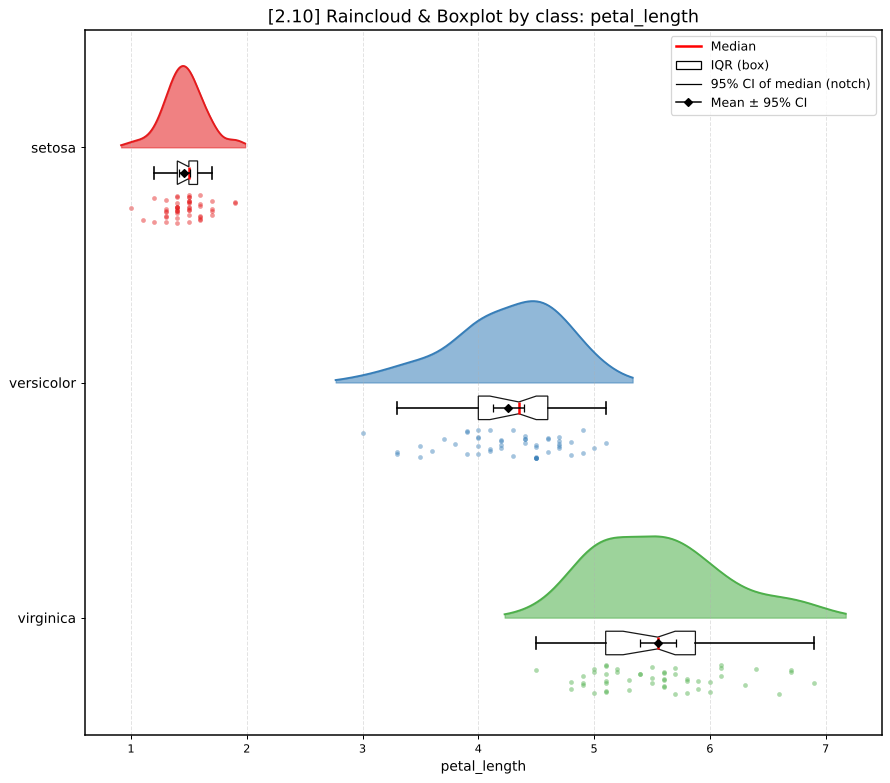

In [11]:
def plot_raincloud_by_class(df, feature, class_col, classes, colors,
                            show_cloud=True, show_box=True, show_rain=True,
                            show_median_ci=True, show_mean_ci=True,
                            ci_level=0.95, n_boot=2000, seed=0, style=None):
    """Облако (KDE) + boxplot (медиана, IQR, ДИ медианы — «вырез», ДИ среднего — усы с ромбом)
    + дождь (точки с джиттерингом) для каждого класса."""
    st = {**DEFAULT_STYLE, **(style or {})}
    rng = np.random.default_rng(seed)
    step = 1.3
    with plt.rc_context({'font.family': st['font_family']}):
        fig, ax = plt.subplots(figsize=(10, 2.6 * len(classes) + 1))
        for k, cls in enumerate(classes):
            vals = df.loc[df[class_col] == cls, feature].dropna().to_numpy()
            base = (len(classes) - 1 - k) * step
            col = colors[cls]

            if show_cloud:
                pad = 0.5 * vals.std()
                xg = np.linspace(vals.min() - pad, vals.max() + pad, 200)
                yk = gaussian_kde(vals)(xg)
                yk = yk / yk.max() * 0.45
                ax.fill_between(xg, base, base + yk, color=col, alpha=0.55)
                ax.plot(xg, base + yk, color=col, lw=1.5)

            if show_box:
                # Доверительный интервал медианы — bootstrap
                boots = np.median(rng.choice(vals, size=(n_boot, len(vals)), replace=True), axis=1)
                a = (1 - ci_level) / 2
                ci_med = np.quantile(boots, [a, 1 - a])
                ax.boxplot(vals, vert=False, positions=[base - 0.14], widths=0.13,
                           patch_artist=True, notch=show_median_ci,
                           conf_intervals=[ci_med] if show_median_ci else None,
                           boxprops=dict(facecolor='white', color='black', alpha=0.9),
                           medianprops=dict(color='red', linewidth=2),
                           whiskerprops=dict(color='black', linewidth=1.3),
                           capprops=dict(color='black', linewidth=1.3),
                           flierprops=dict(marker='', markersize=0))
                if show_mean_ci:
                    # Доверительный интервал среднего — по t-распределению
                    m = vals.mean()
                    h = stats.t.ppf(1 - a, len(vals) - 1) * stats.sem(vals)
                    ax.errorbar(m, base - 0.14, xerr=h, fmt='D', color='black', ms=4,
                                capsize=3, lw=1.2, zorder=6)

            if show_rain:
                jitter = base - 0.34 + rng.uniform(-0.08, 0.08, size=len(vals))
                ax.scatter(vals, jitter, color=col, alpha=st['alpha'] * 0.7, s=st['point_size'] * 0.6,
                           linewidths=0)

        ax.set_yticks([(len(classes) - 1 - k) * step for k in range(len(classes))])
        ax.set_yticklabels([str(c) for c in classes], fontsize=st['font_size_labels'])
        ax.set_xlabel(feature, fontsize=st['font_size_labels'])
        ax.set_ylim(-0.65, (len(classes) - 1) * step + 0.65)
        ax.tick_params(axis='x', labelsize=st['font_size_ticks'])
        ax.grid(st['grid'], axis='x', linestyle='--', alpha=st['grid_alpha'])
        for sp in ax.spines.values():
            sp.set_color(st['color_axes']); sp.set_linewidth(st['lw_axes'])
        if st['show_legend']:
            handles = [plt.Line2D([], [], color='red', lw=2, label='Median'),
                       plt.Rectangle((0, 0), 1, 1, fc='white', ec='black', label='IQR (box)')]
            if show_median_ci:
                handles.append(plt.Line2D([], [], color='black', lw=1, label=f'{int(ci_level*100)}% CI of median (notch)'))
            if show_mean_ci:
                handles.append(plt.Line2D([], [], marker='D', color='black', ms=4, lw=1.2,
                                          label=f'Mean ± {int(ci_level*100)}% CI'))
            ax.legend(handles=handles, fontsize=st['font_size_legend'], loc='upper right', frameon=True)
        if st['show_title']:
            ax.set_title(f'[2.10] Raincloud & Boxplot by class: {feature}', fontsize=st['font_size_title'])
        plt.tight_layout()
        plt.show()

# Признак выбирается пользователем
RAIN_FEATURE = SELECTED_FEATURES[2]
plot_raincloud_by_class(df0m, RAIN_FEATURE, CLASS_COL, SELECTED_CLASSES, CLASS_COLORS)


### 2.11 — Дисперсионный анализ (ANOVA)


In [12]:
def anova_oneway(groups):
    """Однофакторный ANOVA: F, df1 (между группами), df2 (внутри групп), p."""
    groups = [np.asarray(g, float) for g in groups]
    k = len(groups)
    N = sum(len(g) for g in groups)
    grand = np.concatenate(groups).mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ssw = sum(((g - g.mean()) ** 2).sum() for g in groups)
    df1, df2 = k - 1, N - k
    F = (ssb / df1) / (ssw / df2)
    return dict(F=F, df1=df1, df2=df2, p=stats.f.sf(F, df1, df2), SSB=ssb, SSW=ssw)

# Признак выбирается пользователем
ANOVA_FEATURE = SELECTED_FEATURES[2]
data_by_class = {c: df0m.loc[df0m[CLASS_COL] == c, ANOVA_FEATURE].dropna().to_numpy()
                 for c in SELECTED_CLASSES}

total = anova_oneway(list(data_by_class.values()))
# Контроль по scipy
F_sp, p_sp = stats.f_oneway(*data_by_class.values())
assert np.isclose(total['F'], F_sp) and np.isclose(total['p'], p_sp)

print(f"=== [2.11] ANOVA по признаку «{ANOVA_FEATURE}» ===")
print(f"Все классы одновременно: F({total['df1']}, {total['df2']}) = {total['F']:.3f}, "
      f"p = {total['p']:.3e}  (SSB = {total['SSB']:.3f}, SSW = {total['SSW']:.3f})\n")

pair_rows = []
pairs = list(itertools.combinations(SELECTED_CLASSES, 2))
for a, b in pairs:
    r = anova_oneway([data_by_class[a], data_by_class[b]])
    pair_rows.append({'pair': f'{a} vs {b}', 'F': r['F'], 'df1': r['df1'], 'df2': r['df2'],
                      'p': r['p'], 'p (Bonferroni)': min(1.0, r['p'] * len(pairs))})
pair_df = pd.DataFrame(pair_rows).set_index('pair')
print("--- Попарное сравнение классов ---")
display(pair_df.assign(F=pair_df['F'].map('{:.3f}'.format),
                       p=pair_df['p'].map('{:.3e}'.format),
                       **{'p (Bonferroni)': pair_df['p (Bonferroni)'].map('{:.3e}'.format)}))


=== [2.11] ANOVA по признаку «petal_length» ===
Все классы одновременно: F(2, 147) = 1180.161, p = 2.857e-91  (SSB = 437.103, SSW = 27.223)

--- Попарное сравнение классов ---


,F,df1,df2,p,p (Bonferroni)
pair,,,,,
setosa vs versicolor,1559.675,1,98,5.405e-62,1.621e-61
setosa vs virginica,2498.619,1,98,1.505e-71,4.514e-71
versicolor vs virginica,158.855,1,98,3.179e-22,9.536e-22


### 2.12** — Случайный датасет dfG


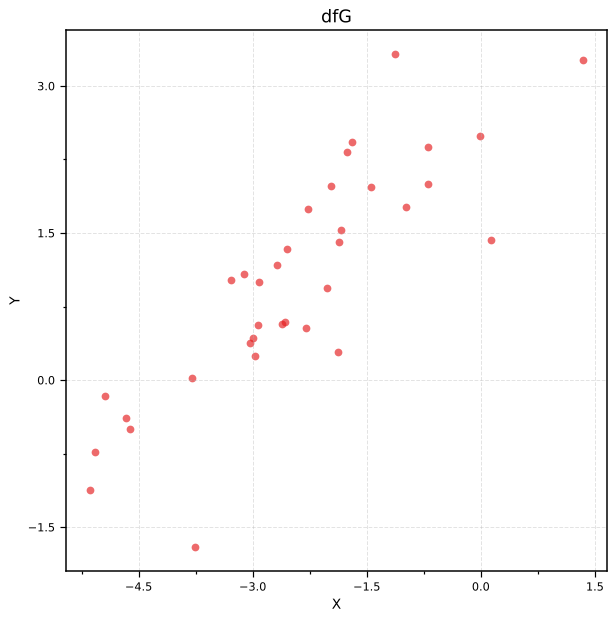

In [13]:
# [2.12] Генерация dfG: два количественных признака, один класс, размер 10–100 объектов.
# Форма облака случайна (задаётся ковариационной матрицей); числа не выводятся.
np.random.seed(11)

n_G = np.random.randint(10, 101)                       # случайный размер 10–100
mean_G = np.random.uniform(-3, 3, size=2)
theta = np.random.uniform(0, np.pi)                    # случайный поворот
lam = np.random.uniform(0.2, 3.0, size=2)              # случайные дисперсии вдоль осей
Rot = np.array([[np.cos(theta), -np.sin(theta)],
                [np.sin(theta),  np.cos(theta)]])
cov_G = Rot @ np.diag(lam) @ Rot.T                     # положительно определённая ковариация

dfG = pd.DataFrame(np.random.multivariate_normal(mean_G, cov_G, size=n_G), columns=['X', 'Y'])
dfG['Class'] = 'Class_1'

# Визуализация dfG
plot_regression_single(dfG, 'Class_1', 'X', 'Y', 'Class', CLASS_COLORS[SELECTED_CLASSES[0]], 'o',
                       show_line=False, show_conf=False, show_pred=False,
                       style=dict(show_legend=False), title='dfG')


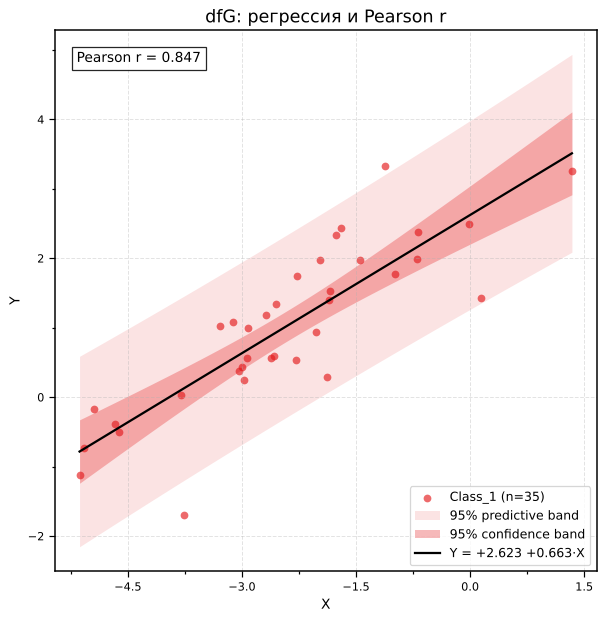

In [14]:
# Повторная визуализация dfG: корреляция Пирсона, линия регрессии, confidence и predictive bands
plot_regression_single(dfG, 'Class_1', 'X', 'Y', 'Class', CLASS_COLORS[SELECTED_CLASSES[0]], 'o',
                       show_line=True, show_conf=True, show_pred=True, show_corr=True,
                       level=0.95, title='dfG: регрессия и Pearson r')
